## Individual Vessel Route Stability, Heading Alignment, and Anchoring (Flag 11)

### Dataset Overview
The case contains 150 AIS-style corridor passages from five cargo vessels, with 30 trajectories per vessel across 15 days. Ordered points provide position, SOG, COG, heading, and navigation status; a vessel table provides static dimensions.

The notebook exposes a primary table and a supporting table (`vessels.csv`).

Goal: Investigate how individual vessels differ in their movement patterns within the corridor.

Role: Maritime trajectory analyst


Category: individual vessel movement-pattern comparison

### Your Objective
Use the provided tables and visual evidence to answer the questions below and summarize the observed trajectory patterns.


## Import Necessary Libraries

This cell loads the data-analysis and visualization libraries used by the questions below.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, SVG, display
points=pd.read_csv('trajectory_points.csv')


## Load Dataset

The primary table is loaded into `df`; when available, the supporting trajectory or driver table is loaded into `user_df`.

In [ ]:
dataset_path = "trajectory_points.csv"
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv(dataset_path)

In [ ]:
user_dataset_path = "vessels.csv"
user_df = pd.read_csv(user_dataset_path)

### **Question 1**: Which vessels repeatedly follow stable corridor routes with aligned heading and COG and smooth heading evolution?

#### Analysis action

Compare repeated geometries by vessel, then calculate circular heading differences within each ordered trajectory.

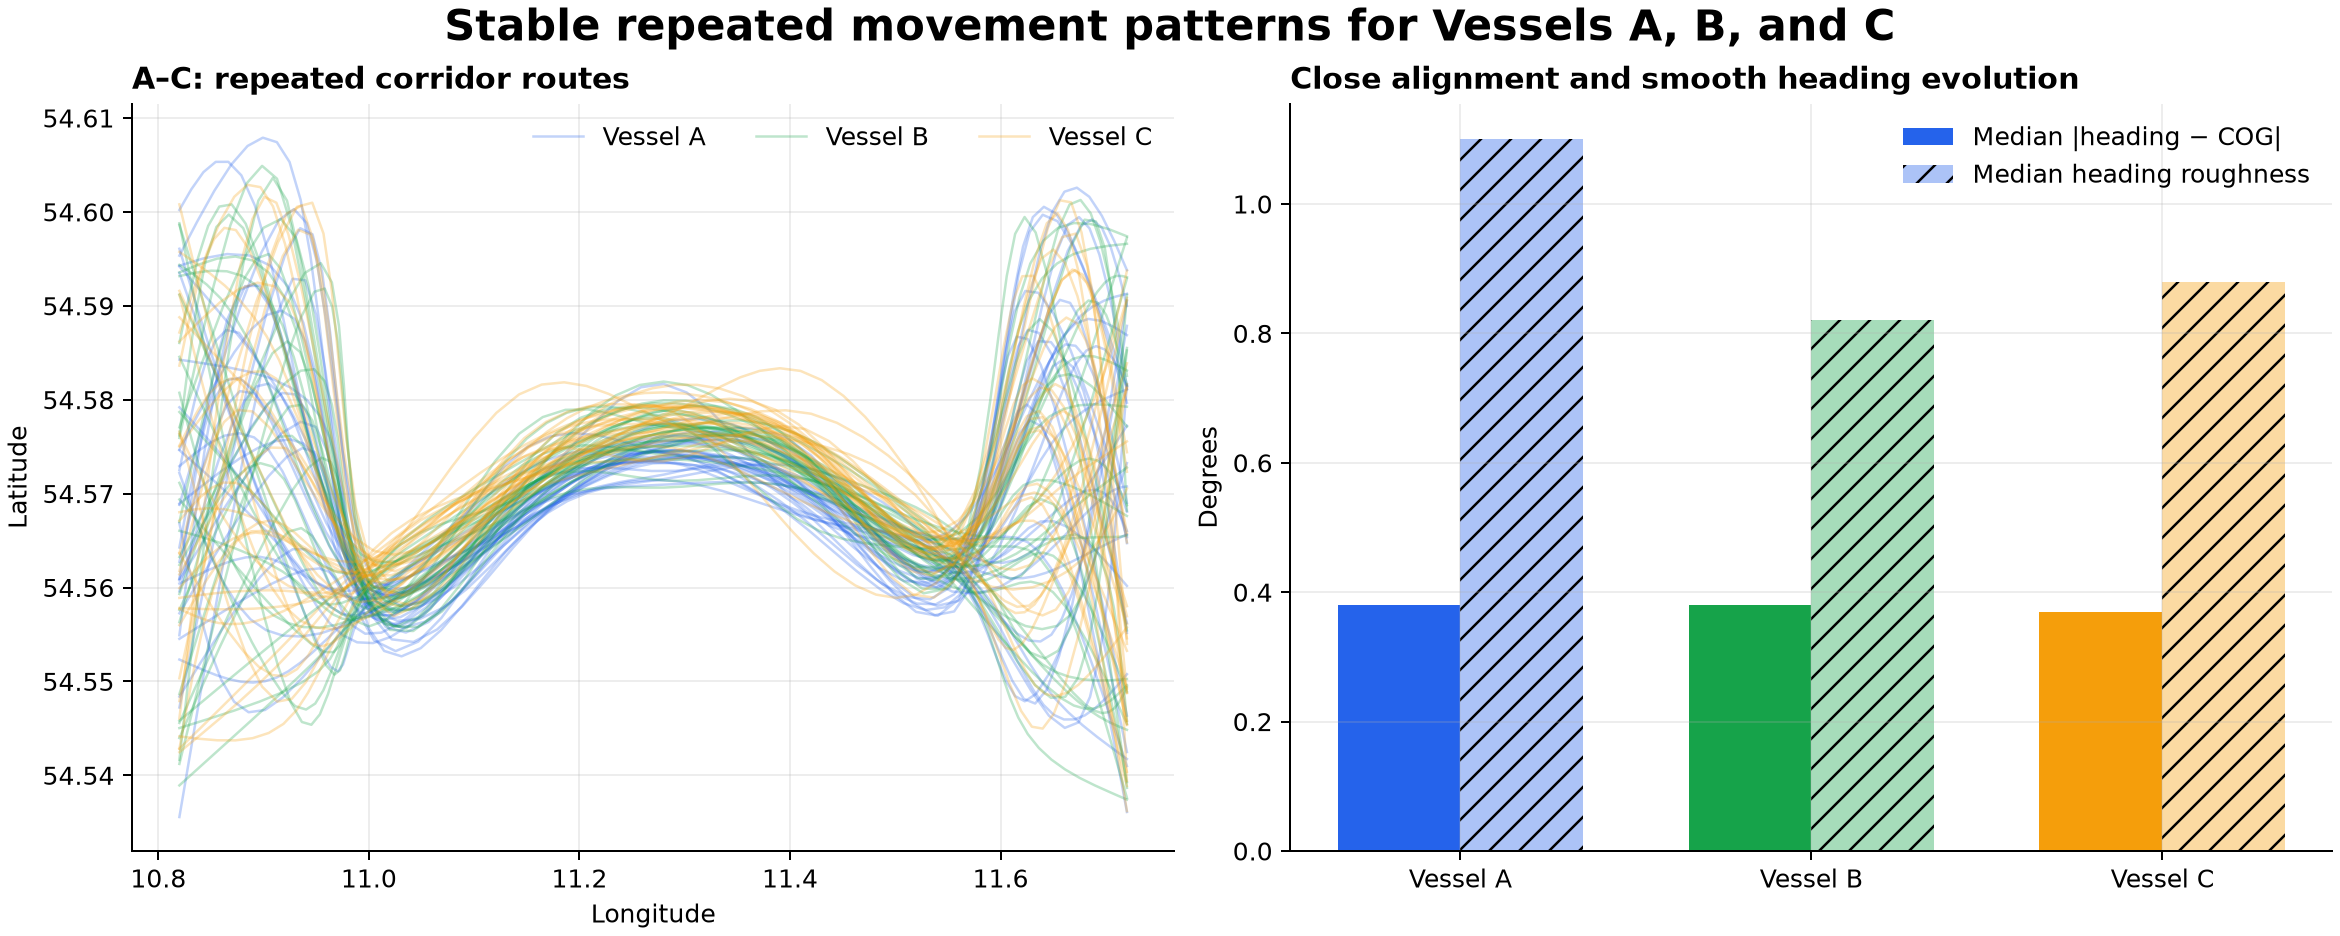

In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv(dataset_path).sort_values(['trajectory_id','point_index'])
df['heading_cog_gap'] = np.abs((df.heading-df.cog+180)%360-180)
print(df.groupby('vessel_id')['heading_cog_gap'].median())
from IPython.display import Image, display
display(Image(filename='visualizations/stable_routes_heading_alignment.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "repeated_route_and_heading_stability",
  "insight": "Vessels A, B, and C repeatedly traverse the corridor along relatively stable routes, with close alignment between heading and COG and smooth changes in heading.",
  "insight_value": {
    "trajectories_per_vessel": 30,
    "mean_route_dispersion_nautical_miles": {
      "Vessel A": 0.24,
      "Vessel B": 0.25,
      "Vessel C": 0.25
    },
    "median_heading_cog_gap_deg": {
      "Vessel A": 0.38,
      "Vessel B": 0.38,
      "Vessel C": 0.37
    },
    "median_heading_roughness_deg": {
      "Vessel A": 1.1,
      "Vessel B": 0.82,
      "Vessel C": 0.88
    }
  },
  "plot": {
    "plot_type": "route_overlay_and_heading_metric_comparison",
    "title": "Stable Repeated Routes and Heading Alignment for Vessels A–C",
    "file": "visualizations/stable_routes_heading_alignment.png",
    "description": "Repeated route overlays show the narrow paths of A–C; grouped bars summarize heading–COG alignment and heading roughness."
  },
  "question": "Which vessels repeatedly follow stable corridor routes with aligned heading and COG and smooth heading evolution?",
  "actionable_insight": "Compare repeated geometries by vessel, then calculate circular heading differences within each ordered trajectory.",
  "code": "import pandas as pd\nimport numpy as np\ndf = pd.read_csv(dataset_path).sort_values(['trajectory_id','point_index'])\ndf['heading_cog_gap'] = np.abs((df.heading-df.cog+180)%360-180)\nprint(df.groupby('vessel_id')['heading_cog_gap'].median())",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "heading",
    "course_over_ground",
    "trajectory_timestamp"
  ]
}

### **Question 2**: How do the route variability and heading–COG differences of Vessels D and E compare with those of Vessels A, B, and C?

#### Analysis action

Normalize repeated trajectories to a common longitude grid before comparing route dispersion, and use circular rather than ordinary angular differences.

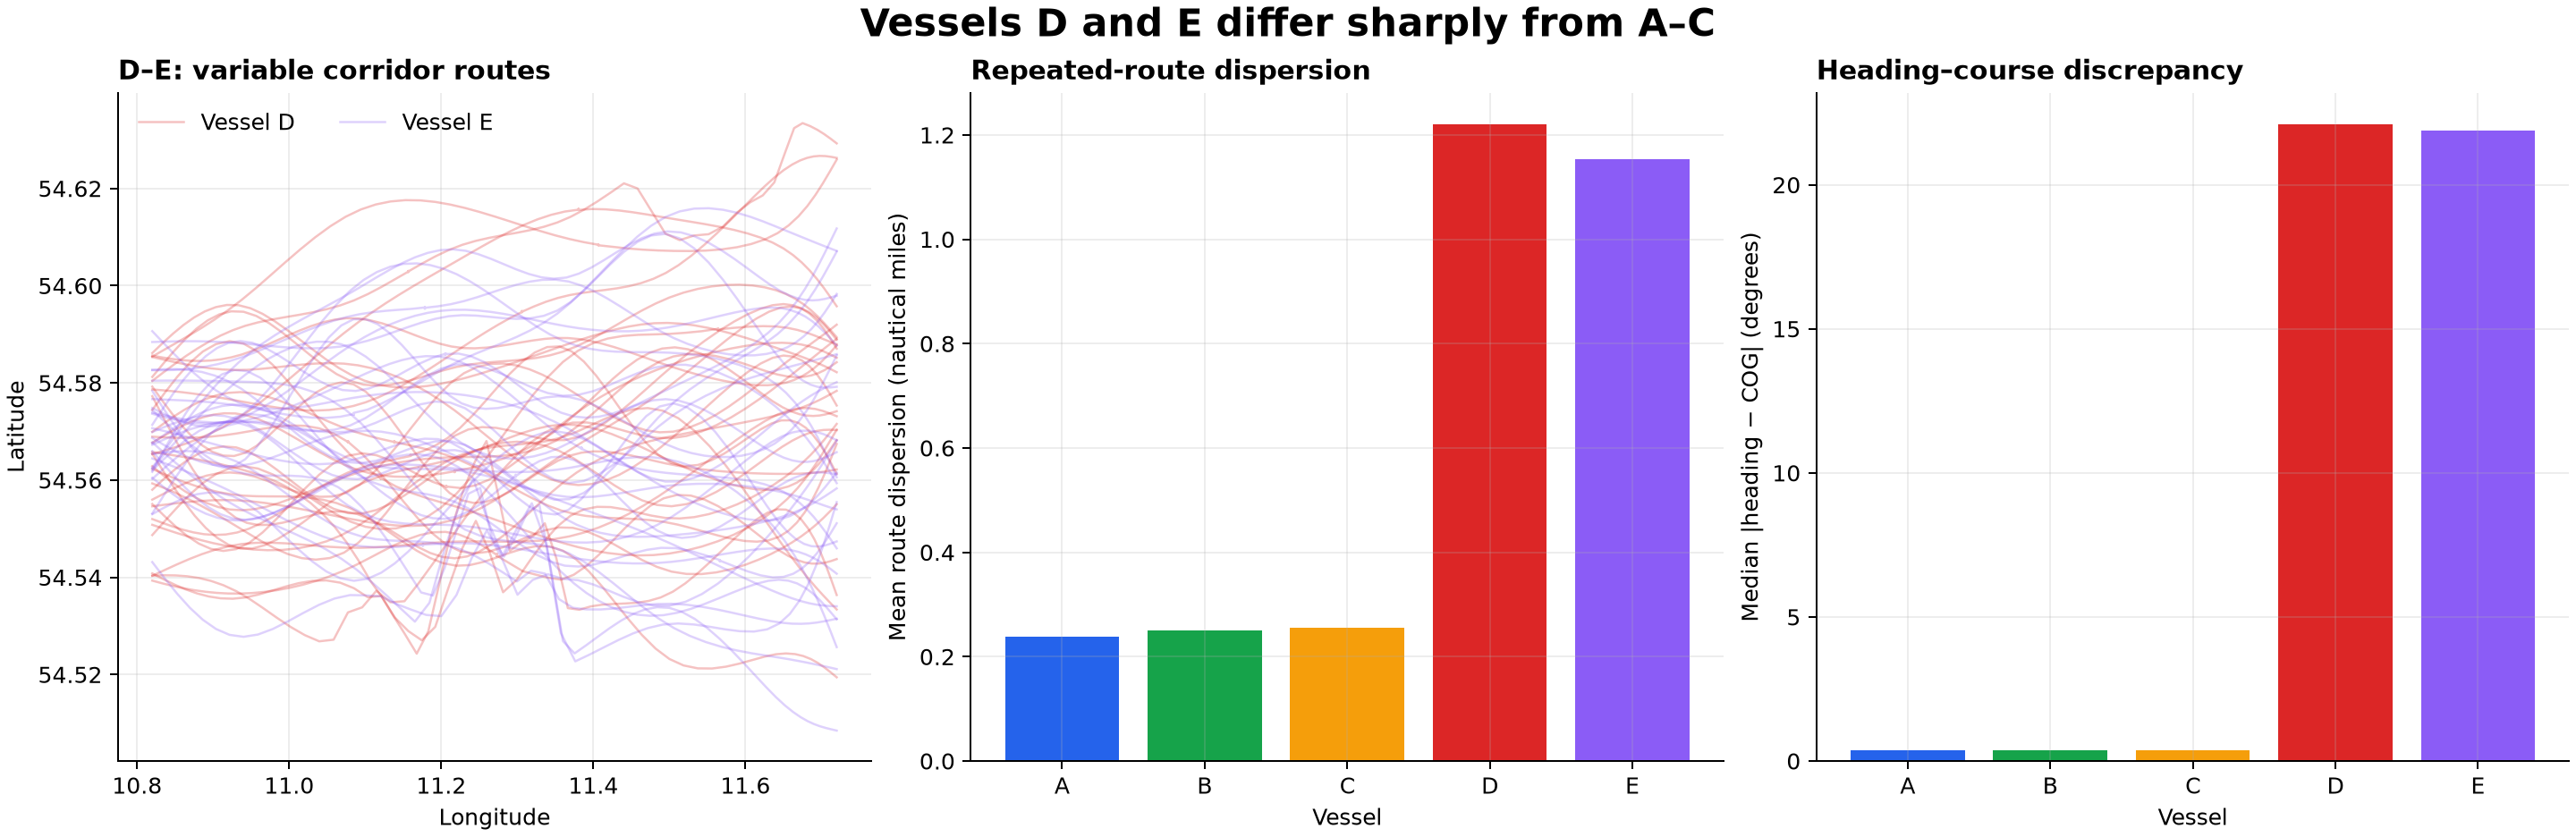

In [ ]:
import pandas as pd
import numpy as np
df = pd.read_csv(dataset_path)
df['heading_cog_gap'] = np.abs((df.heading-df.cog+180)%360-180)
print(df.groupby('vessel_id')['heading_cog_gap'].median())
# Interpolate each trajectory on a shared longitude grid and compare the across-trajectory latitude SD by vessel.
from IPython.display import Image, display
display(Image(filename='visualizations/variable_routes_heading_gap.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: High (5 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "between_vessel_route_and_heading_variability",
  "insight": "Vessels D and E follow more variable routes across the corridor and show substantially larger differences between heading and COG.",
  "insight_value": {
    "mean_route_dispersion_nautical_miles": {
      "Vessel A": 0.24,
      "Vessel B": 0.25,
      "Vessel C": 0.25,
      "Vessel D": 1.22,
      "Vessel E": 1.15
    },
    "median_heading_cog_gap_deg": {
      "Vessel A": 0.38,
      "Vessel B": 0.38,
      "Vessel C": 0.37,
      "Vessel D": 22.09,
      "Vessel E": 21.88
    },
    "comparison": "D and E versus A, B, and C"
  },
  "plot": {
    "plot_type": "route_overlay_and_grouped_metric_comparison",
    "title": "Route Variability and Heading–COG Difference by Vessel",
    "file": "visualizations/variable_routes_heading_gap.png",
    "description": "D–E route overlays are paired with vessel-level route dispersion and circular heading–COG gap comparisons."
  },
  "question": "How do the route variability and heading–COG differences of Vessels D and E compare with those of Vessels A, B, and C?",
  "actionable_insight": "Normalize repeated trajectories to a common longitude grid before comparing route dispersion, and use circular rather than ordinary angular differences.",
  "code": "import pandas as pd\nimport numpy as np\ndf = pd.read_csv(dataset_path)\ndf['heading_cog_gap'] = np.abs((df.heading-df.cog+180)%360-180)\nprint(df.groupby('vessel_id')['heading_cog_gap'].median())\n# Interpolate each trajectory on a shared longitude grid and compare the across-trajectory latitude SD by vessel.",
  "insight_type": "overall_pattern",
  "difficulty_level": 5,
  "difficulty_label": "high",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "heading",
    "course_over_ground",
    "trajectory_timestamp"
  ]
}

### **Question 3**: Which vessels frequently stop or anchor during a corridor passage before continuing?

#### Analysis action

Count distinct trajectories with at least one At anchor point so that multiple stationary AIS reports do not inflate the comparison.

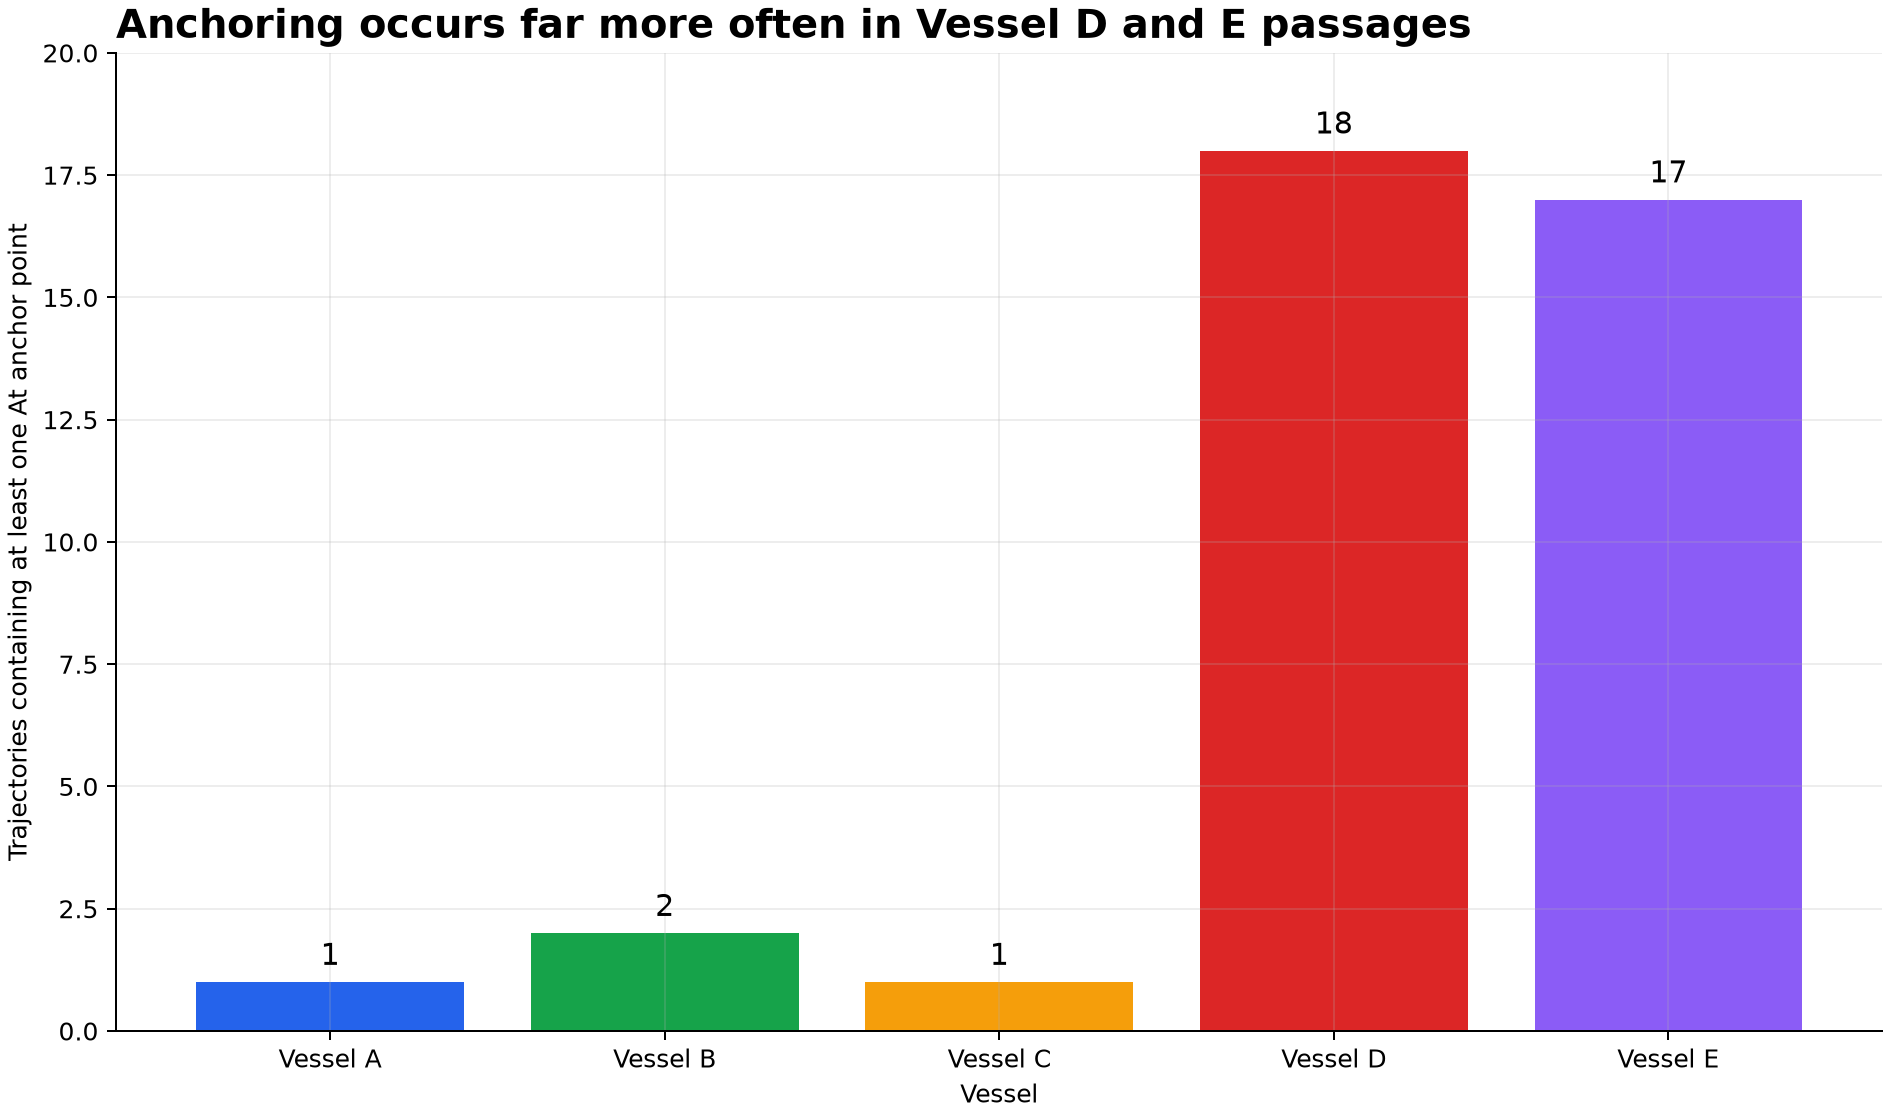

In [ ]:
import pandas as pd
df = pd.read_csv(dataset_path)
anchored = df[df.nav_status.eq('At anchor')].groupby('vessel_id').trajectory_id.nunique()
print(anchored)
from IPython.display import Image, display
display(Image(filename='visualizations/anchoring_frequency.png'))


#### Generate JSON Description for the Insight

**Insight difficulty: Medium (4 required native or equivalent independent inputs).**


In [ ]:
{
  "data_type": "vessel_group_anchoring_frequency",
  "insight": "Compared with Vessels A, B, and C, Vessels D and E frequently stop or anchor during their passages before continuing through the corridor.",
  "insight_value": {
    "trajectories_per_vessel": 30,
    "trajectories_with_at_anchor_status": {
      "Vessel A": 1,
      "Vessel B": 2,
      "Vessel C": 1,
      "Vessel D": 18,
      "Vessel E": 17
    },
    "frequent_anchoring_group": [
      "Vessel D",
      "Vessel E"
    ]
  },
  "plot": {
    "plot_type": "anchored_trajectory_count_bar_chart",
    "title": "Passages Containing an Anchoring Event by Vessel",
    "file": "visualizations/anchoring_frequency.png",
    "description": "Each trajectory is counted once if any of its ordered AIS points has At anchor navigation status."
  },
  "question": "Which vessels frequently stop or anchor during a corridor passage before continuing?",
  "actionable_insight": "Count distinct trajectories with at least one At anchor point so that multiple stationary AIS reports do not inflate the comparison.",
  "code": "import pandas as pd\ndf = pd.read_csv(dataset_path)\nanchored = df[df.nav_status.eq('At anchor')].groupby('vessel_id').trajectory_id.nunique()\nprint(anchored)",
  "insight_type": "group_comparison",
  "difficulty_level": 4,
  "difficulty_label": "medium",
  "difficulty_version": "3.5",
  "difficulty_is_provisional": false,
  "difficulty_field_dependencies": [
    "vessel_id",
    "gps_position",
    "navigation_status",
    "trajectory_timestamp"
  ]
}

### Summary of Findings (Flag 11)

Vessels A, B, and C repeatedly follow narrow, heading-aligned corridor routes. Vessels D and E use routes about five times more dispersed, maintain heading–COG gaps around 22 degrees rather than below half a degree, and anchor during 18 and 17 of their 30 passages, respectively.
